In [1]:
import os
import glob
import random
import cv2
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import timm

In [2]:
# 1. Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [3]:
# 2. Aggressive Social Media Compression Function
def apply_social_media_compression(img_bgr):
    """
    Simulates aggressive social media pipeline: 
    Downscale -> Chroma Subsampling (JPEG) -> Gaussian Blur -> Upscale
    """
    h, w, _ = img_bgr.shape
    
    # Step 1: Aggressive Downscaling (mimicking platform resizing)
    scale_factor = random.uniform(0.8, 1.0)
    new_h, new_w = int(h * scale_factor), int(w * scale_factor)
    img_resized = cv2.resize(img_bgr, (new_w, new_h), interpolation=cv2.INTER_AREA)
    img_resized = cv2.resize(img_resized, (w, h), interpolation=cv2.INTER_LINEAR)
    
    # Step 2: Apply a mild Gaussian Blur
    if random.random() < 0.7:
        img_resized = cv2.GaussianBlur(img_resized, (5, 5), 0)
        
    # Step 3: Extreme JPEG Compression with Chroma Subsampling
    quality = random.randint(10, 25)
    encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
    _, encimg = cv2.imencode('.jpg', img_resized, encode_param)
    decimg_bgr = cv2.imdecode(encimg, 1)
    
    # Convert to RGB for PIL / PyTorch
    return cv2.cvtColor(decimg_bgr, cv2.COLOR_BGR2RGB)

In [4]:
# 3. 140k Dataset Class with Compression Support
class BalancedDeepfakeDataset(Dataset):
    def __init__(self, split='train', base_dir='/kaggle/input', transform=None, seed=42, compression_prob=0.5):
        self.transform = transform
        self.compression_prob = compression_prob
        self.image_paths = []
        self.labels = []
        self.rng = random.Random(seed)
        
        # Map split names to the 140k dataset folder structure
        split_map = {'train': 'train', 'val': 'valid', 'test': 'test'}
        target_split = split_map.get(split, split)
        
        print(f"[{split.upper()}] Locating 140k dataset in {base_dir}...")
        dataset_path = self._auto_discover_140k(base_dir)
        if not dataset_path:
            raise FileNotFoundError(f"Could not find 140k dataset ('real-vs-fake') inside {base_dir}")
            
        split_dir = os.path.join(dataset_path, target_split)
        
        # 140k dataset has 'real' (label 0) and 'fake' (label 1)
        real_dir = os.path.join(split_dir, 'real')
        fake_dir = os.path.join(split_dir, 'fake')
        
        real_paths = []
        fake_paths = []
        for ext in ('*.png', '*.jpg', '*.jpeg'):
            real_paths.extend(glob.glob(os.path.join(real_dir, ext)))
            fake_paths.extend(glob.glob(os.path.join(fake_dir, ext)))
            
        # Ensure 1:1 balance between real and fake
        min_count = min(len(real_paths), len(fake_paths))
        if min_count == 0:
            raise ValueError(f"❌ ERROR: No images found for split '{split}' in {split_dir}")
            
        sampled_real = self.rng.sample(real_paths, min_count)
        sampled_fake = self.rng.sample(fake_paths, min_count)
        
        self.image_paths = sampled_real + sampled_fake
        self.labels = [0] * min_count + [1] * min_count
        
        # Shuffle together
        combined = list(zip(self.image_paths, self.labels))
        self.rng.shuffle(combined)
        self.image_paths, self.labels = zip(*combined)
        self.image_paths = list(self.image_paths)
        self.labels = list(self.labels)
        
        print(f"✅ Final {split} dataset size: {len(self.image_paths)} images ready (Real: {min_count}, Fake: {min_count}).\n")

    def _auto_discover_140k(self, base_dir):
        # Automatically search for 'real-vs-fake' or the directory holding train/valid/test
        for root, dirs, files in os.walk(base_dir):
            if 'real-vs-fake' in dirs:
                return os.path.join(root, 'real-vs-fake')
            if 'train' in dirs and 'valid' in dirs and 'test' in dirs:
                return root
        return None

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]
        
        # Load image via CV2 to match the compression pipeline
        img_bgr = cv2.imread(img_path)
        
        # Dynamically apply compression function
        if self.rng.random() < self.compression_prob:
            img_rgb = apply_social_media_compression(img_bgr)
        else:
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            
        # Convert to PIL for Torchvision transforms
        img_pil = Image.fromarray(img_rgb)
        
        if self.transform:
            img_tensor = self.transform(img_pil)
            
        return img_tensor, torch.tensor(label, dtype=torch.long)

In [5]:
# 4. Define Transforms for Xception (299x299)
def get_data_transforms(img_size=299):
    norm_mean = [0.485, 0.456, 0.406]
    norm_std = [0.229, 0.224, 0.225]

    train_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.RandomCrop(img_size, padding=4, padding_mode='reflect'),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05),
        transforms.ToTensor(),
        transforms.Normalize(mean=norm_mean, std=norm_std)
    ])

    val_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=norm_mean, std=norm_std)
    ])

    return train_transform, val_transform

In [6]:
# 5. Initialize Datasets and DataLoaders
train_transform, val_transform = get_data_transforms(img_size=299)

# Set compression probability to 0.7 for training, 0.0 for validation/testing
train_dataset = BalancedDeepfakeDataset(split='train', transform=train_transform, seed=42, compression_prob=0.7)
val_dataset   = BalancedDeepfakeDataset(split='val', transform=val_transform, seed=42, compression_prob=0.0)
test_dataset  = BalancedDeepfakeDataset(split='test', transform=val_transform, seed=42, compression_prob=0.0)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

[TRAIN] Locating 140k dataset in /kaggle/input...
✅ Final train dataset size: 100000 images ready (Real: 50000, Fake: 50000).

[VAL] Locating 140k dataset in /kaggle/input...
✅ Final val dataset size: 20000 images ready (Real: 10000, Fake: 10000).

[TEST] Locating 140k dataset in /kaggle/input...
✅ Final test dataset size: 20000 images ready (Real: 10000, Fake: 10000).



In [7]:
# 6. Define & Initialize SpatialDeepfakeDetector Model
class SpatialDeepfakeDetector(nn.Module):
    def __init__(self, pretrained=True, drop_rate=0.3):
        super(SpatialDeepfakeDetector, self).__init__()
        
        # Load Xception backbone
        self.backbone = timm.create_model('xception', pretrained=pretrained)
        
        # Replace the classifier head (2048 -> 512 -> 1)
        num_ftrs = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Linear(num_ftrs, 512),
            nn.ReLU(),
            nn.Dropout(p=drop_rate),
            nn.Linear(512, 1)
        )

    def forward(self, x):
        return self.backbone(x)


DROPOUT_RATE = 0.1

print("Loading Xception model with custom head...")
model = SpatialDeepfakeDetector(pretrained=True, drop_rate=DROPOUT_RATE)
model = model.to(device)

Loading Xception model with custom head...


/usr/local/lib/python3.12/dist-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth


In [8]:
# 7. Quick verification test
images, labels = next(iter(train_loader))
images = images.to(device)
outputs = model(images)
print(f"Batch images shape: {images.shape} (Expected: [32, 3, 299, 299])")
print(f"Model outputs shape: {outputs.shape} (Expected: [32, 1])")

Batch images shape: torch.Size([32, 3, 299, 299]) (Expected: [32, 3, 299, 299])
Model outputs shape: torch.Size([32, 1]) (Expected: [32, 1])


In [9]:
# Fetch one batch to verify
images, labels = next(iter(train_loader))
print(f"Batch images tensor shape: {images.shape}")
print(f"Batch labels: {labels}")

Batch images tensor shape: torch.Size([32, 3, 299, 299])
Batch labels: tensor([0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1,
        0, 0, 1, 0, 0, 1, 1, 1])


In [10]:
import torchvision
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import timm

In [11]:
def imshow(inp, title=None):
    """Imshow for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0))
    
    # Un-normalize 
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    
    plt.figure(figsize=(12, 8))
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.axis('off')
    plt.show()

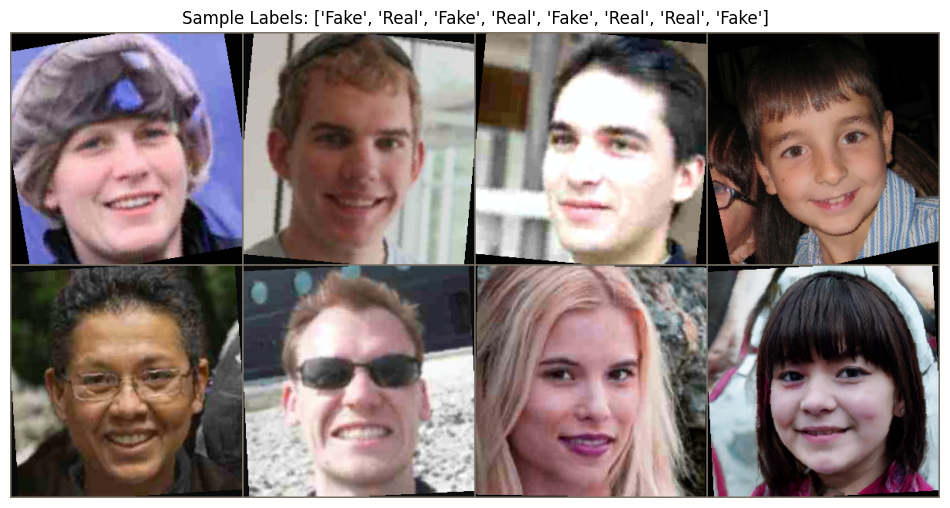

In [12]:
# Grab a single batch
images, labels = next(iter(train_loader))

num_images_to_show = 8
images_to_show = images[:num_images_to_show]
labels_to_show = labels[:num_images_to_show]

out = torchvision.utils.make_grid(images_to_show, nrow=4)
label_mapping = {0: "Real", 1: "Fake"}
titles = [label_mapping[int(label.item())] for label in labels_to_show]

imshow(out, title=f"Sample Labels: {titles}")

In [13]:
# Test the model output shape
images = images.to(device) 
with torch.no_grad():
    outputs = model(images)

print(f"Output tensor shape: {outputs.shape}")
print("If you see torch.Size([32, 1]), the Xception model is ready!")

Output tensor shape: torch.Size([32, 1])
If you see torch.Size([32, 1]), the Xception model is ready!


In [14]:
import torch.optim as optim
from tqdm import tqdm
import copy
from torch.optim.lr_scheduler import ReduceLROnPlateau

In [15]:
# 1. Define Loss Function
criterion = nn.BCEWithLogitsLoss()

In [16]:
# 2. Define Optimizer (Split learning rates)
backbone_params = []
classifier_params = []
for name, param in model.named_parameters():
    if "backbone.fc" in name:
        classifier_params.append(param)
    else:
        backbone_params.append(param)

optimizer = optim.AdamW([
    {'params':  backbone_params, 'lr': 3e-5}, # Slow updates to features
    {'params': classifier_params, 'lr': 3e-4}       # Fast updates to the head
])

In [17]:
# 3. Early Stopping Class
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0, verbose=True):
        self.patience = patience
        self.min_delta = min_delta
        self.verbose = verbose
        self.counter = 0
        self.best_loss = float('inf')
        self.early_stop = False
        self.best_model_wts = None

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss - self.min_delta:
            if self.verbose:
                print(f"Validation loss decreased ({self.best_loss:.4f} --> {val_loss:.4f}). Saving model weights...")
            self.best_loss = val_loss
            self.best_model_wts = copy.deepcopy(model.state_dict())
            self.counter = 0
        else:
            self.counter += 1
            print(f"EarlyStopping counter: {self.counter} out of {self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True

In [18]:
# 4. Training Loop Setup
epochs = 10 # Adjusted for Kaggle limits
early_stopper = EarlyStopping(patience=3, verbose=True)
scheduler = ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.1)

STOP_TOLERANCE = 3
stop_count = 0

for epoch in range(epochs):
    # --- TRAINING PHASE ---
    model.train()
    running_loss = 0.0
    current_lr = optimizer.param_groups[0]['lr']
    
    # Using miniters to reduce tqdm log spam in background runs
    loop = tqdm(train_loader, total=len(train_loader), leave=True, miniters=100)
    
    for inputs, labels in loop:
        inputs = inputs.to(device)
        labels = labels.to(device).view(-1, 1).float() # Required for BCEWithLogitsLoss
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        loop.set_description(f"Epoch [{epoch+1}/{epochs}] (LR: {current_lr:.1e})")
        
    avg_train_loss = running_loss / len(train_loader)
    print(f"\nEpoch {epoch+1}/{epochs} Completed - Average Train Loss: {avg_train_loss:.4f}")
    
    # --- VALIDATION PHASE ---
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0
    
    val_loop = tqdm(val_loader, total=len(val_loader), leave=False, miniters=100)
    
    with torch.no_grad():
        for inputs, labels in val_loop:
            inputs = inputs.to(device)
            labels = labels.to(device).view(-1, 1).float()
            
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            
            predictions = (torch.sigmoid(outputs) > 0.5).float()
            correct += (predictions == labels).sum().item()
            total += labels.size(0)
            
    avg_val_loss = val_loss / len(val_loader)
    val_accuracy = (correct / total) * 100
    print(f"Epoch {epoch+1}/{epochs} Validation - Loss: {avg_val_loss:.4f} | Acc: {val_accuracy:.2f}%")

    # Save Checkpoint
    torch.save(model.state_dict(), f"xception_deepfake_detector_epoch_{epoch+1}.pth")

    # Step the scheduler and early stopper
    scheduler.step(avg_val_loss)
    early_stopper(avg_val_loss, model)
    
    if early_stopper.early_stop:
        print(f"Early stopping triggered at Epoch {epoch+1}. Training stopped.")
        break

# Load the absolute best weights recorded
if early_stopper.best_model_wts is not None:
    print("Loading best model weights from validation tracking...")
    model.load_state_dict(early_stopper.best_model_wts)

Epoch [1/10] (LR: 3.0e-05): 100%|██████████| 3125/3125 [53:53<00:00,  1.03s/it]



Epoch 1/10 Completed - Average Train Loss: 0.2731


Epoch 1/10 Validation - Loss: 0.0452 | Acc: 98.39%
Validation loss decreased (inf --> 0.0452). Saving model weights...


Epoch [2/10] (LR: 3.0e-05): 100%|██████████| 3125/3125 [54:00<00:00,  1.04s/it]



Epoch 2/10 Completed - Average Train Loss: 0.1379


...


Epoch 9/10 Completed - Average Train Loss: 0.0283


Epoch 9/10 Validation - Loss: 0.0075 | Acc: 99.76%
Validation loss decreased (0.0078 --> 0.0075). Saving model weights...


Epoch [10/10] (LR: 3.0e-05): 100%|██████████| 3125/3125 [54:00<00:00,  1.04s/it]



Epoch 10/10 Completed - Average Train Loss: 0.0257


Epoch 10/10 Validation - Loss: 0.0090 | Acc: 99.70%
EarlyStopping counter: 1 out of 3
Loading best model weights from validation tracking...


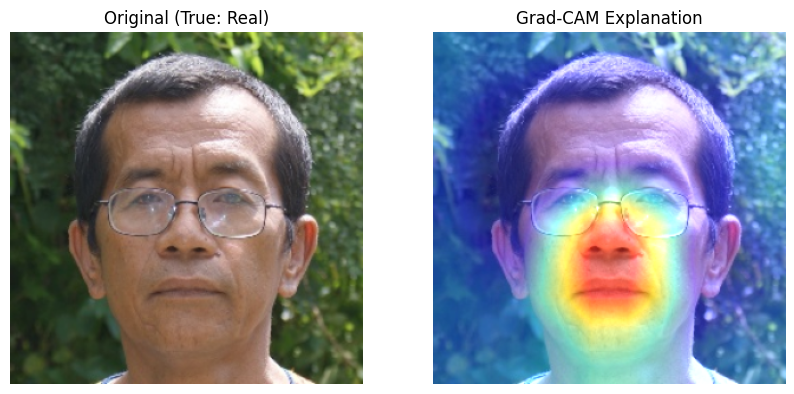

In [19]:
import torch.nn.functional as F
import cv2
import numpy as np

# Unfreeze layers for GradCAM (Ensures gradients can flow)
for param in model.backbone.parameters():
    param.requires_grad = True

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_tensor):
        model_output = self.model(input_tensor)
        self.model.zero_grad()
        
        # --- FIX FOR 1-NODE OUTPUT ---
        # model_output is shape [1, 1]. We must isolate the scalar logit.
        logit = model_output[0, 0]
        logit.backward(retain_graph=True)
        # -----------------------------
        
        pooled_gradients = torch.mean(self.gradients, dim=[0, 2, 3])
        activations = self.activations.detach()[0]
        for i in range(activations.shape[0]):
            activations[i, :, :] *= pooled_gradients[i]
            
        heatmap = torch.mean(activations, dim=0).squeeze().cpu().numpy()
        heatmap = np.maximum(heatmap, 0)
        if np.max(heatmap) != 0:
            heatmap /= np.max(heatmap)
        return heatmap

# Target the deepest convolutional layer in Xception
target_layer = model.backbone.conv4 
cam = GradCAM(model, target_layer)

model.eval() 
sample_img, sample_label = next(iter(test_loader)) # Use test loader for unseen data
sample_img = sample_img[0:1].to(device)

heatmap = cam.generate_heatmap(sample_img)

# --- VISUALIZATION ---
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)
disp_img = inv_normalize(sample_img[0].cpu())
disp_img = disp_img.permute(1, 2, 0).numpy()
disp_img = np.clip(disp_img, 0, 1)

heatmap_resized = cv2.resize(heatmap, (299, 299))
heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
heatmap_colored = np.float32(heatmap_colored) / 255
heatmap_colored = heatmap_colored[..., ::-1] 

overlay = heatmap_colored * 0.5 + disp_img
overlay = np.clip(overlay, 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(disp_img)
axes[0].set_title(f"Original (True: {'Fake' if sample_label[0].item() == 1 else 'Real'})")
axes[0].axis('off')

axes[1].imshow(overlay)
axes[1].set_title("Grad-CAM Explanation")
axes[1].axis('off')

plt.show()

Starting Final Evaluation on Test Set...


Testing: 100%|██████████| 625/625 [03:23<00:00,  3.07it/s]



--- Final XceptionNet Performance ---
Accuracy:  99.76%
Precision: 99.78%
Recall:    99.73%
F1-Score:  99.75%


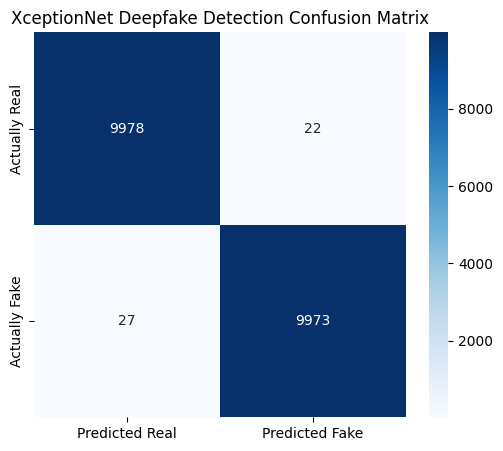

Model weights successfully saved!


In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt # Added just in case plt wasn't imported in this specific cell

print("Starting Final Evaluation on Test Set...")

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc="Testing"):
        inputs = inputs.to(device)
        labels = labels.to(device).view(-1, 1).float()
        
        outputs = model(inputs)
        probs = torch.sigmoid(outputs)
        preds = (probs > 0.5).float()
        
        # --- ADDED .flatten() HERE ---
        all_preds.extend(preds.cpu().numpy().flatten())
        all_labels.extend(labels.cpu().numpy().flatten())

acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds, zero_division=0)
rec = recall_score(all_labels, all_preds, zero_division=0)
f1 = f1_score(all_labels, all_preds, zero_division=0)

print("\n--- Final XceptionNet Performance ---")
print(f"Accuracy:  {acc * 100:.2f}%")
print(f"Precision: {prec * 100:.2f}%")
print(f"Recall:    {rec * 100:.2f}%")
print(f"F1-Score:  {f1 * 100:.2f}%")

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted Real', 'Predicted Fake'], 
            yticklabels=['Actually Real', 'Actually Fake'])
plt.title('XceptionNet Deepfake Detection Confusion Matrix')
plt.show()

torch.save(model.state_dict(), 'xception_deepfake_detector_final.pth')
print("Model weights successfully saved!")